# Customer Acquisition & Segmentation Analytics

**Portfolio case study · Python / pandas / statistics / visualization**

**Question:** How are customers distributed across regions and segments, and does recorded acquisition cost differ across those groups?

This notebook works from a **privacy-reduced** extract (`data/public/customer_analytics.csv`), rather than publishing the original customer master with names and detailed addresses. The dataset has no acquisition dates, campaign attribution, revenue, or known currency. These figures are *recorded per-customer cost*, not validated return-on-ad-spend (ROAS) or conversion-rate metrics. Statistical tests are exploratory only.

## 1. Set up and load data

Import libraries, then load the version-controlled analytical extract. Paths work both from the repository root and from the `notebooks` folder.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "data/public/customer_analytics.csv").exists(), "Open notebook from the project or notebooks directory"

df = pd.read_csv(ROOT / "data/public/customer_analytics.csv", dtype={"record_id": "string"})
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
display(df.head())

Rows: 25,000 | Columns: 8


,record_id,customer_age,gender,customer_segment,customer_country,region,customer_acquisition_cost,postal_format_check
0,ANON-000001,48,Female,Premium,India,South,43.90,format_mismatch
1,ANON-000002,45,Male,Business,UK,West,37.99,format_mismatch
2,ANON-000003,34,Female,Consumer,USA,Central,8.42,matches_pattern
3,ANON-000004,20,Female,Premium,USA,Central,32.30,matches_pattern
4,ANON-000005,53,Male,Premium,UK,North,39.35,format_mismatch


## 2. Understand the data

Review types, missing values, duplicate *analysis IDs* and invalid numeric values. The IDs were reassigned while preparing the public extract; they are not real customer identifiers.

In [2]:
print(df.dtypes.to_string())
checks = pd.Series({
    "Rows": len(df),
    "Missing values": int(df.isna().sum().sum()),
    "Duplicate analysis IDs": int(df.record_id.duplicated().sum()),
    "Invalid ages": int((~df.customer_age.between(18, 110)).sum()),
    "Negative costs": int((df.customer_acquisition_cost < 0).sum()),
})
display(checks.rename("result").to_frame())

record_id                    string[python]
customer_age                          int64
gender                               object
customer_segment                     object
customer_country                     object
region                               object
customer_acquisition_cost           float64
postal_format_check                  object


,result
Rows,25000
Missing values,0
Duplicate analysis IDs,0
Invalid ages,0
Negative costs,0


## 3. Audit geographical data quality

Before the original postal codes were removed, country-specific **format patterns** were applied to the source. The extract contains only the outcome of that check, not the literal postal codes. A formatting pass does not establish whether an address exists.

In [3]:
postal_checks = pd.crosstab(df.customer_country, df.postal_format_check)
display(postal_checks)
print("Format mismatches:", int(df.postal_format_check.eq("format_mismatch").sum()))
print("Not checked:", int(df.postal_format_check.eq("not_checked").sum()))

postal_format_check,format_mismatch,matches_pattern,not_checked
customer_country,,,
Australia,1233,0,0
Canada,1279,0,0
Germany,0,2046,0
India,1041,0,0
UAE,0,0,775
UK,3701,0,0
USA,0,14925,0


Format mismatches: 7254
Not checked: 775


## 4. Feature engineering

Age bands and quartile labels make distribution comparisons easier. Cost quartiles are defined **relative to these records**, not as business-defined spending tiers.

In [4]:
data = df.copy()
age_labels = ["18–24", "25–34", "35–44", "45–54", "55–64", "65+"]
data["age_group"] = pd.cut(data.customer_age, bins=[17,24,34,44,54,64,np.inf], labels=age_labels)
q1, q2, q3 = data.customer_acquisition_cost.quantile([.25,.5,.75])
data["cost_quartile"] = pd.cut(data.customer_acquisition_cost,
    bins=[-np.inf,q1,q2,q3,np.inf], labels=["Q1", "Q2", "Q3", "Q4"])
display(data[["customer_age","age_group","customer_acquisition_cost","cost_quartile"]].head())

,customer_age,age_group,customer_acquisition_cost,cost_quartile
0,48,45–54,43.90,Q3
1,45,45–54,37.99,Q2
2,34,25–34,8.42,Q1
3,20,18–24,32.30,Q2
4,53,45–54,39.35,Q2


## 5. Establish KPIs

Count records, markets and segments. Sum of the recorded costs is not necessarily a total advertising budget.

In [5]:
kpis = pd.Series({
    "Customer records": len(data),
    "Countries": data.customer_country.nunique(),
    "Segments": data.customer_segment.nunique(),
    "Mean recorded cost (unknown units)": round(data.customer_acquisition_cost.mean(), 2),
    "Median cost (unknown units)": round(data.customer_acquisition_cost.median(), 2),
    "Sum of cost entries (unknown units)": round(data.customer_acquisition_cost.sum(), 2),
    "Mean age (years)": round(data.customer_age.mean(), 1),
})
display(kpis.rename("value").to_frame())

,value
Customer records,25000.00
Countries,7.00
Segments,4.00
Mean recorded cost (unknown units),42.16
Median cost (unknown units),41.98
Sum of cost entries (unknown units),1053993.76
Mean age (years),45.90


## 6. Segment and country distributions

A large segment has more total cost *because it has more records*. Average cost is the more relevant comparison here, but it is still not a verified measure of campaign efficiency.

In [6]:
def summarize(group_field):
    table = data.groupby(group_field, observed=True).agg(
        customers=("record_id", "count"),
        mean_cost=("customer_acquisition_cost", "mean"),
        total_recorded_cost=("customer_acquisition_cost", "sum"),
    ).sort_values("customers", ascending=False)
    table["share_pct"] = 100 * table.customers / len(data)
    return table

segments = summarize("customer_segment")
countries = summarize("customer_country")
display(segments.round(2))
display(countries.round(2))

,customers,mean_cost,total_recorded_cost,share_pct
customer_segment,,,,
Consumer,13638,42.26,576384.01,54.55
Premium,6301,41.94,264258.98,25.20
VIP,2542,41.93,106596.11,10.17
Business,2519,42.38,106754.66,10.08


,customers,mean_cost,total_recorded_cost,share_pct
customer_country,,,,
USA,14925,42.09,628131.77,59.70
UK,3701,42.27,156458.71,14.80
Germany,2046,42.22,86377.15,8.18
Canada,1279,42.61,54501.58,5.12
Australia,1233,42.97,52985.41,4.93
India,1041,41.83,43546.68,4.16
UAE,775,41.28,31992.46,3.10


## 7. Visualize the customer mix

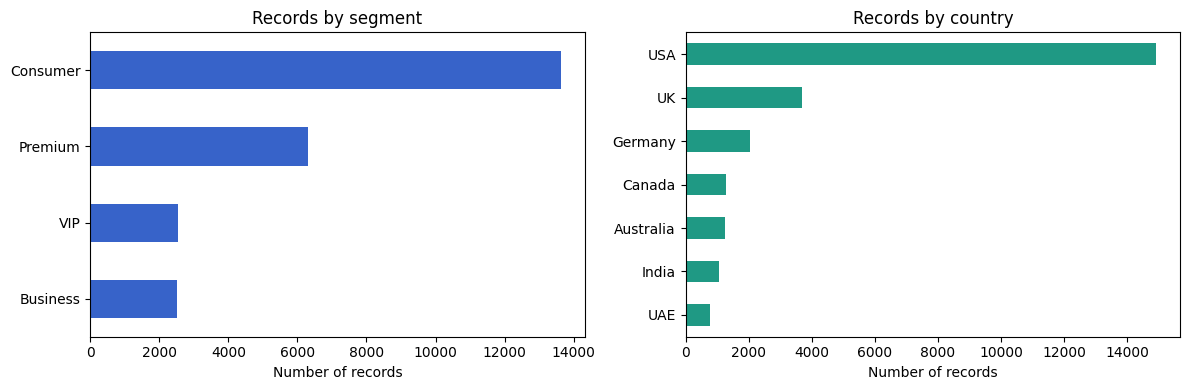

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
segments.customers.sort_values().plot(kind="barh", ax=axes[0], color="#3763c9")
axes[0].set_title("Records by segment")
axes[0].set_xlabel("Number of records")
axes[0].set_ylabel("")
countries.customers.sort_values().plot(kind="barh", ax=axes[1], color="#1f9984")
axes[1].set_title("Records by country")
axes[1].set_xlabel("Number of records")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

## 8. Distribution of acquisition cost and age

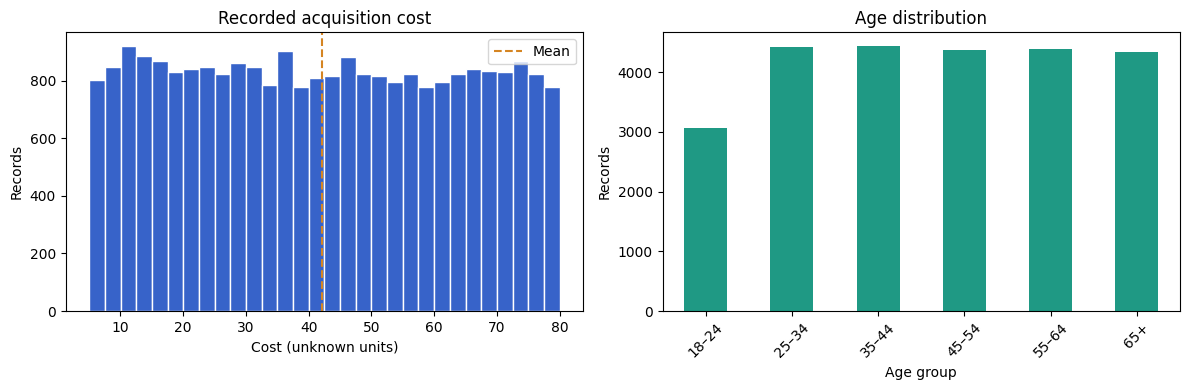

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(data.customer_acquisition_cost, bins=30, color="#3763c9", edgecolor="white")
axes[0].axvline(data.customer_acquisition_cost.mean(), color="#d58522", ls="--", label="Mean")
axes[0].legend()
axes[0].set(title="Recorded acquisition cost", xlabel="Cost (unknown units)", ylabel="Records")
data.age_group.value_counts().reindex(age_labels).plot(kind="bar", ax=axes[1], color="#1f9984")
axes[1].set(title="Age distribution", xlabel="Age group", ylabel="Records")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 9. Composition within each country

Normalize by country to compare segment composition fairly across differently sized countries.

customer_segment,Business,Consumer,Premium,VIP
customer_country,,,,
Australia,10.9,53.6,25.1,10.4
Canada,10.0,53.2,27.1,9.7
Germany,9.3,55.7,25.3,9.7
India,11.0,52.4,25.7,10.8
UAE,9.5,53.9,25.9,10.6
UK,9.8,55.0,24.8,10.5
USA,10.2,54.6,25.1,10.1


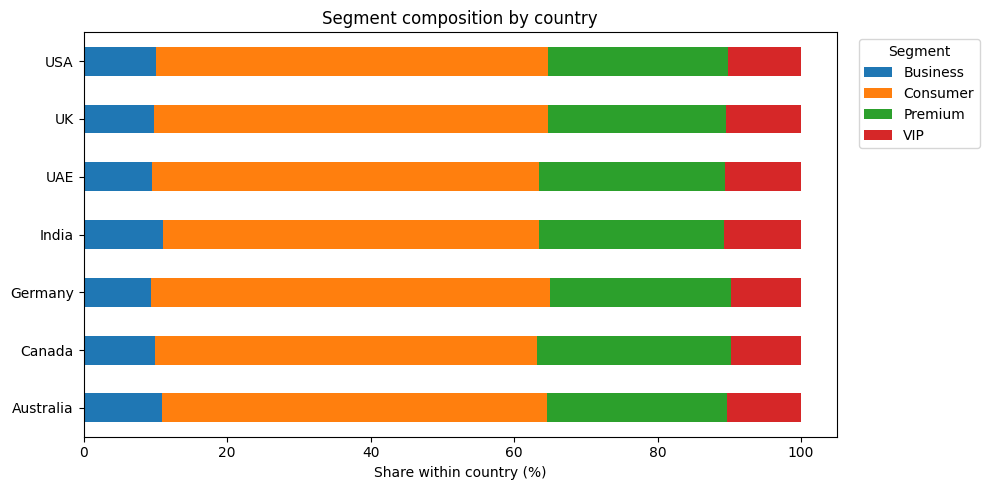

In [9]:
ct = pd.crosstab(data.customer_country, data.customer_segment)
country_segment_pct = ct.div(ct.sum(axis=1), axis=0).mul(100)
display(country_segment_pct.round(1))
country_segment_pct.plot(kind="barh", stacked=True, figsize=(10, 5))
plt.title("Segment composition by country")
plt.xlabel("Share within country (%)")
plt.ylabel("")
plt.legend(title="Segment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 10. Explore statistical evidence

ANOVA compares group means. Eta-squared describes the share of observed cost variation explained by groups in this sample. A high p-value is **not** proof that groups are identical. Pearson correlation assesses *linear* association only; none of these tests establishes causality.

In [10]:
def anova_test(group_name):
    groups = [g.customer_acquisition_cost.to_numpy() for _,g in data.groupby(group_name)]
    f, p = stats.f_oneway(*groups)
    overall = data.customer_acquisition_cost
    between = sum(len(g) * (g.mean() - overall.mean())**2 for g in groups)
    eta_squared = between / ((overall - overall.mean())**2).sum()
    return pd.Series({"F": f, "p": p, "eta_squared": eta_squared})

results = pd.DataFrame({
    "Segments": anova_test("customer_segment"),
    "Countries": anova_test("customer_country"),
}).T
r, p_age = stats.pearsonr(data.customer_age, data.customer_acquisition_cost)
display(results.round(5))
print(f"Age vs cost: Pearson r={r:.5f}, p={p_age:.4f}")

,F,p,eta_squared
Segments,0.49841,0.68338,0.00006
Countries,0.68197,0.66425,0.00016


Age vs cost: Pearson r=0.00021, p=0.9735


## 11. Business interpretation and limitations

**Findings**

- The USA accounts for **59.7%** of records; Consumer accounts for **54.6%**.
- Mean recorded acquisition cost is **42.16 unspecified units**.
- Differences in mean cost across markets and segments are negligible in this dataset; no reliable group-specific cost advantage is established.
- The postal-format audit flags **7,254** source records for format review. This is not postal-address verification.

**Recommendations**

1. Validate provenance and geographic labels before using this data to target customers.
2. Add acquisition dates, channel, campaign, budget, revenue and retention fields before attempting channel CAC or ROI analysis.
3. Consider this a descriptive portfolio demonstration; the source may be simulated and is not verified market intelligence.

See [`README.md`](../README.md), [`reports/analysis_report.md`](../reports/analysis_report.md), and the filterable HTML dashboard for the published deliverables.